In [2]:
# 피쳐에 대한 정보입니다.
# 이정보를 가지고 피쳐에 대한 연봉예측 ai를 구현하시오.
# picher_stats_2017.csv

In [3]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 판다스 관련 import
import pandas as pd
import numpy as np

# 인공지능 import
from sklearn import svm,metrics # 분류와 숫자 예측에 사용하는 모델 모음,모델의 예측 성능을 평가하는 도구 모음
from sklearn.neighbors import KNeighborsClassifier  #분류(가까운 이웃 데이터를 참고해 종류를 분류)
from sklearn.neighbors import KNeighborsRegressor   #예측(가까운 이웃데이터를 참고해 숫자를 예측)

from sklearn.preprocessing import PolynomialFeatures # 다항특성 (x², x₁ × x₂ 같은 특성을 추가)
from sklearn.preprocessing import OneHotEncoder      # 원핫인코딩(문자형 번주를 0과1로 변환)

from sklearn.linear_model import LinearRegression   #예측 (입력과 결과의 선형관례를 학습해 숫자를 예측)
from sklearn.linear_model import Ridge              #릿지 (계수가 지나치게 커지는 것을 억제하는 선형 회귀)
from sklearn.linear_model import Lasso              #라쏘 (일부 계수를 0으로 만들어 특성 선택에도 활용하는 선형 회귀)
from sklearn.linear_model import LogisticRegression #분류
from sklearn.linear_model import SGDClassifier

from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위 (실제값과 예측값의 차이를 절댓값으로 구한 뒤 평균 계산)
from sklearn.preprocessing import StandardScaler # 표준화 (각 특성을 평균 0, 표준편차 1 기준으로 표준화)
from sklearn.model_selection import train_test_split #(데이터를 학습용과 평가용으로 분리)
from scipy.special import expit                     #exip:이진분류함수
from scipy.special import softmax                   #softmax: 다중분류함수

# 결정트리
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree                  #그래프지원

# 교차검증
from sklearn.model_selection import cross_validate      # 자동 반복

# 분할기
from sklearn.model_selection import StratifiedKFold

from sklearn.model_selection import GridSearchCV

In [4]:
# 피쳐에 대한정보입니다.
# 이 정보를 가지고 피쳐에 대한 연봉예측 linearGegression를 구현하시오.


In [5]:
df= pd.read_csv('data/picher_stats_2017.csv')
df.head(2)

,선수명,팀명,승,패,세,홀드,블론,경기,선발,이닝,...,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017)
0,켈리,SK,16,7,0,0,0,30,30,190.0,...,0.76,0.342,73.7,3.60,6.91,3.69,3.44,6.62,140000,85000
1,소사,LG,11,11,1,0,0,30,29,185.1,...,0.53,0.319,67.1,3.88,6.80,3.52,3.41,6.08,120000,50000


In [6]:
df.columns

Index(['선수명', '팀명', '승', '패', '세', '홀드', '블론', '경기', '선발', '이닝', '삼진/9',
       '볼넷/9', '홈런/9', 'BABIP', 'LOB%', 'ERA', 'RA9-WAR', 'FIP', 'kFIP', 'WAR',
       '연봉(2018)', '연봉(2017)'],
      dtype='str')

In [7]:
df.info()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 152 entries, 0 to 151
Data columns (total 22 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   선수명       152 non-null    str    
 1   팀명        152 non-null    str    
 2   승         152 non-null    int64  
 3   패         152 non-null    int64  
 4   세         152 non-null    int64  
 5   홀드        152 non-null    int64  
 6   블론        152 non-null    int64  
 7   경기        152 non-null    int64  
 8   선발        152 non-null    int64  
 9   이닝        152 non-null    float64
 10  삼진/9      152 non-null    float64
 11  볼넷/9      152 non-null    float64
 12  홈런/9      152 non-null    float64
 13  BABIP     152 non-null    float64
 14  LOB%      152 non-null    float64
 15  ERA       152 non-null    float64
 16  RA9-WAR   152 non-null    float64
 17  FIP       152 non-null    float64
 18  kFIP      152 non-null    float64
 19  WAR       152 non-null    float64
 20  연봉(2018)  152 non-null    int64  
 21  연봉(2

(152, 22)

In [8]:
data=df[list(df.columns[2:-2]) + [df.columns[-1]]].values
label= df['연봉(2018)'].values
print(data.shape)
print(label.shape)

(152, 19)
(152,)


In [9]:
data[:2]

array([[1.600e+01, 7.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 3.000e+01,
        3.000e+01, 1.900e+02, 8.950e+00, 2.130e+00, 7.600e-01, 3.420e-01,
        7.370e+01, 3.600e+00, 6.910e+00, 3.690e+00, 3.440e+00, 6.620e+00,
        8.500e+04],
       [1.100e+01, 1.100e+01, 1.000e+00, 0.000e+00, 0.000e+00, 3.000e+01,
        2.900e+01, 1.851e+02, 7.430e+00, 1.850e+00, 5.300e-01, 3.190e-01,
        6.710e+01, 3.880e+00, 6.800e+00, 3.520e+00, 3.410e+00, 6.080e+00,
        5.000e+04]])

In [10]:
# 데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(data,label,test_size=0.2,random_state=42)

In [11]:
# linearGegression
# 선형 회귀 모델 생성
lr=LinearRegression()
lr.fit(train_data, train_label)
# 학습에 사용하지 않은 선수들의 연봉 예측
predict= lr.predict(test_data)
print(predict)

# 정확도
print('train정확도 : ',lr.score(train_data,train_label))
print('test정확도 : ',lr.score(test_data,test_label))

[ 10058.26861056   5066.32313413  -8684.99514586 -10548.41156761
  21148.7938011    3070.28792709  32356.7741007   24834.82284151
  11680.56495279  53112.72996105   2714.38568233   4411.25403996
   -717.97998754  70253.22918968    832.08963005  85294.72533055
    645.49948417  19693.60914166   1557.61796843   4079.86796616
   -668.04149417   5522.22228841   3865.64505991  28542.14477614
   7668.33920615   3233.60873557  54026.25796616  -3130.11763069
   9298.61680322   7006.96005118    453.64058016]
train정확도 :  0.9241030973077544
test정확도 :  0.8684464171701025


In [12]:
# 정규화 후 릿지규제

# 정규화 : 
ss=StandardScaler()

train_scaled = ss.fit_transform(train_data)
test_scaled = ss.transform(test_data)

In [13]:
# 2. 릿지모델 학습
# alpha: 릿지 모델에서 규제의 강도를 정하는 값, 숫자가 클수록 규제가 강함
# 너무 작으면 훈련 데이터에 지나치게 맞추는 과적합 / 너무 크면 필요한 관계까지 충분히 학습하지 못하는 과소적합이 생길수 있음
ridge=Ridge(alpha=1)
ridge.fit(train_scaled, train_label)

# 3. 연봉 예측
predict = ridge.predict(test_scaled)
print(predict)

# 4. 정확도
print('train정확도:', ridge.score(train_scaled, train_label))
print('test정확도:', ridge.score(test_scaled, test_label))



[ 1.03068600e+04  3.64718460e+03 -7.78447084e+03 -9.59645084e+03
  1.93651868e+04  3.24933469e+03  3.15385432e+04  2.53251022e+04
  1.40217720e+04  5.38503158e+04  3.08763915e+03  4.63811907e+03
 -3.06395774e+01  7.13879778e+04  1.32594659e+03  8.56221277e+04
  9.81365997e+02  1.93948127e+04  1.09742493e+03  4.65683044e+03
 -2.24322979e+02  7.59943052e+03  4.32511843e+03  2.72507795e+04
  7.04592319e+03  3.16433337e+03  5.36744429e+04 -2.86625541e+03
  9.69032534e+03  8.63620710e+03  1.48796944e+03]
train정확도: 0.9238116713102946
test정확도: 0.8737031403375574


In [14]:
#  그리드를 써서 for문 대신해보기
# train_scaled를 5부분으로 나눕니다.
# 4부분으로 학습하고, 남은 1부분으로 검증합니다.
# 검증할 부분을 바꾸면서 5번 반복합니다.
# 이 과정을 alpha 6개 각각에 대해 수행합니다.
params={
    'alpha':[0.001,0.01,0.1,1,10,100]
}
gs=GridSearchCV(Ridge(),params, return_train_score=True)
gs.fit(train_scaled, train_label)

print("최고 정확도 : ",gs.best_score_)

ridge=gs.best_estimator_
print('가장좋은 모델:',ridge)
print('train정확도 :',ridge.score(train_scaled,train_label))
print('test정확도 :',ridge.score(test_scaled,test_label))

print("가장좋은 파라미터 : ",gs.best_params_)
print(gs.cv_results_['mean_train_score'])
print(gs.cv_results_['mean_test_score'])


최고 정확도 :  0.8651453824131451
가장좋은 모델: Ridge(alpha=10)
train정확도 : 0.9172010716207588
test정확도 : 0.875529936253929
가장좋은 파라미터 :  {'alpha': 10}
[0.92917984 0.92897912 0.92877211 0.92812281 0.91809501 0.79667895]
[0.83778083 0.84189925 0.84516996 0.85322208 0.86514538 0.76561309]


# 선생님꺼 따라하기

In [15]:
# 데이터 가져오기
picher = pd.read_csv('data/picher_stats_2017.csv')
picher.head(2)

,선수명,팀명,승,패,세,홀드,블론,경기,선발,이닝,...,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017)
0,켈리,SK,16,7,0,0,0,30,30,190.0,...,0.76,0.342,73.7,3.60,6.91,3.69,3.44,6.62,140000,85000
1,소사,LG,11,11,1,0,0,30,29,185.1,...,0.53,0.319,67.1,3.88,6.80,3.52,3.41,6.08,120000,50000


In [18]:
# 데이터 분리
# picher = picher.rename(columns={'연봉(2018)': 'y'}) # 컬럼명 변경
data = picher[picher.columns.difference(['선수명','팀명','연봉(2018)'])]
team = picher['팀명']
label = picher['연봉(2018)']

In [19]:
# 원핫인코딩
from sklearn.preprocessing import OneHotEncoder

team = team.to_numpy().reshape(-1,1)
# 원핫인코딩 객체 생성 / NumPy 배열로 반환 / 0 부분 1개 삭제, True,False가 아닌 1,0
encoder = OneHotEncoder(sparse_output=False,drop='first', dtype=int)
# 원핫인코딩 적용
result = encoder.fit_transform(team)
# 숫자 데이터 + 원핫인코딩 결합
total_data = np.concatenate((data, result), axis=1)
total_data

array([[ 0.342,  3.6  ,  3.69 , ...,  0.   ,  0.   ,  0.   ],
       [ 0.319,  3.88 ,  3.52 , ...,  0.   ,  0.   ,  0.   ],
       [ 0.332,  3.44 ,  3.94 , ...,  0.   ,  0.   ,  0.   ],
       ...,
       [ 0.382, 11.66 ,  8.03 , ...,  1.   ,  0.   ,  0.   ],
       [ 0.341,  5.77 ,  6.87 , ...,  0.   ,  1.   ,  0.   ],
       [ 0.312,  7.67 ,  7.6  , ...,  0.   ,  0.   ,  0.   ]],
      shape=(152, 27))

In [20]:
# 데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(total_data,label,random_state=42)

In [21]:
# 정규화작업
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data) 

In [22]:
alpha_list = [0.001,0.01,0.1,1,10,100]
# 릿지, 라쏘 규제 2가지 형태
train_score = []
test_score = []
for alpha in alpha_list:
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    # 정확도
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)
print('완료') 

완료


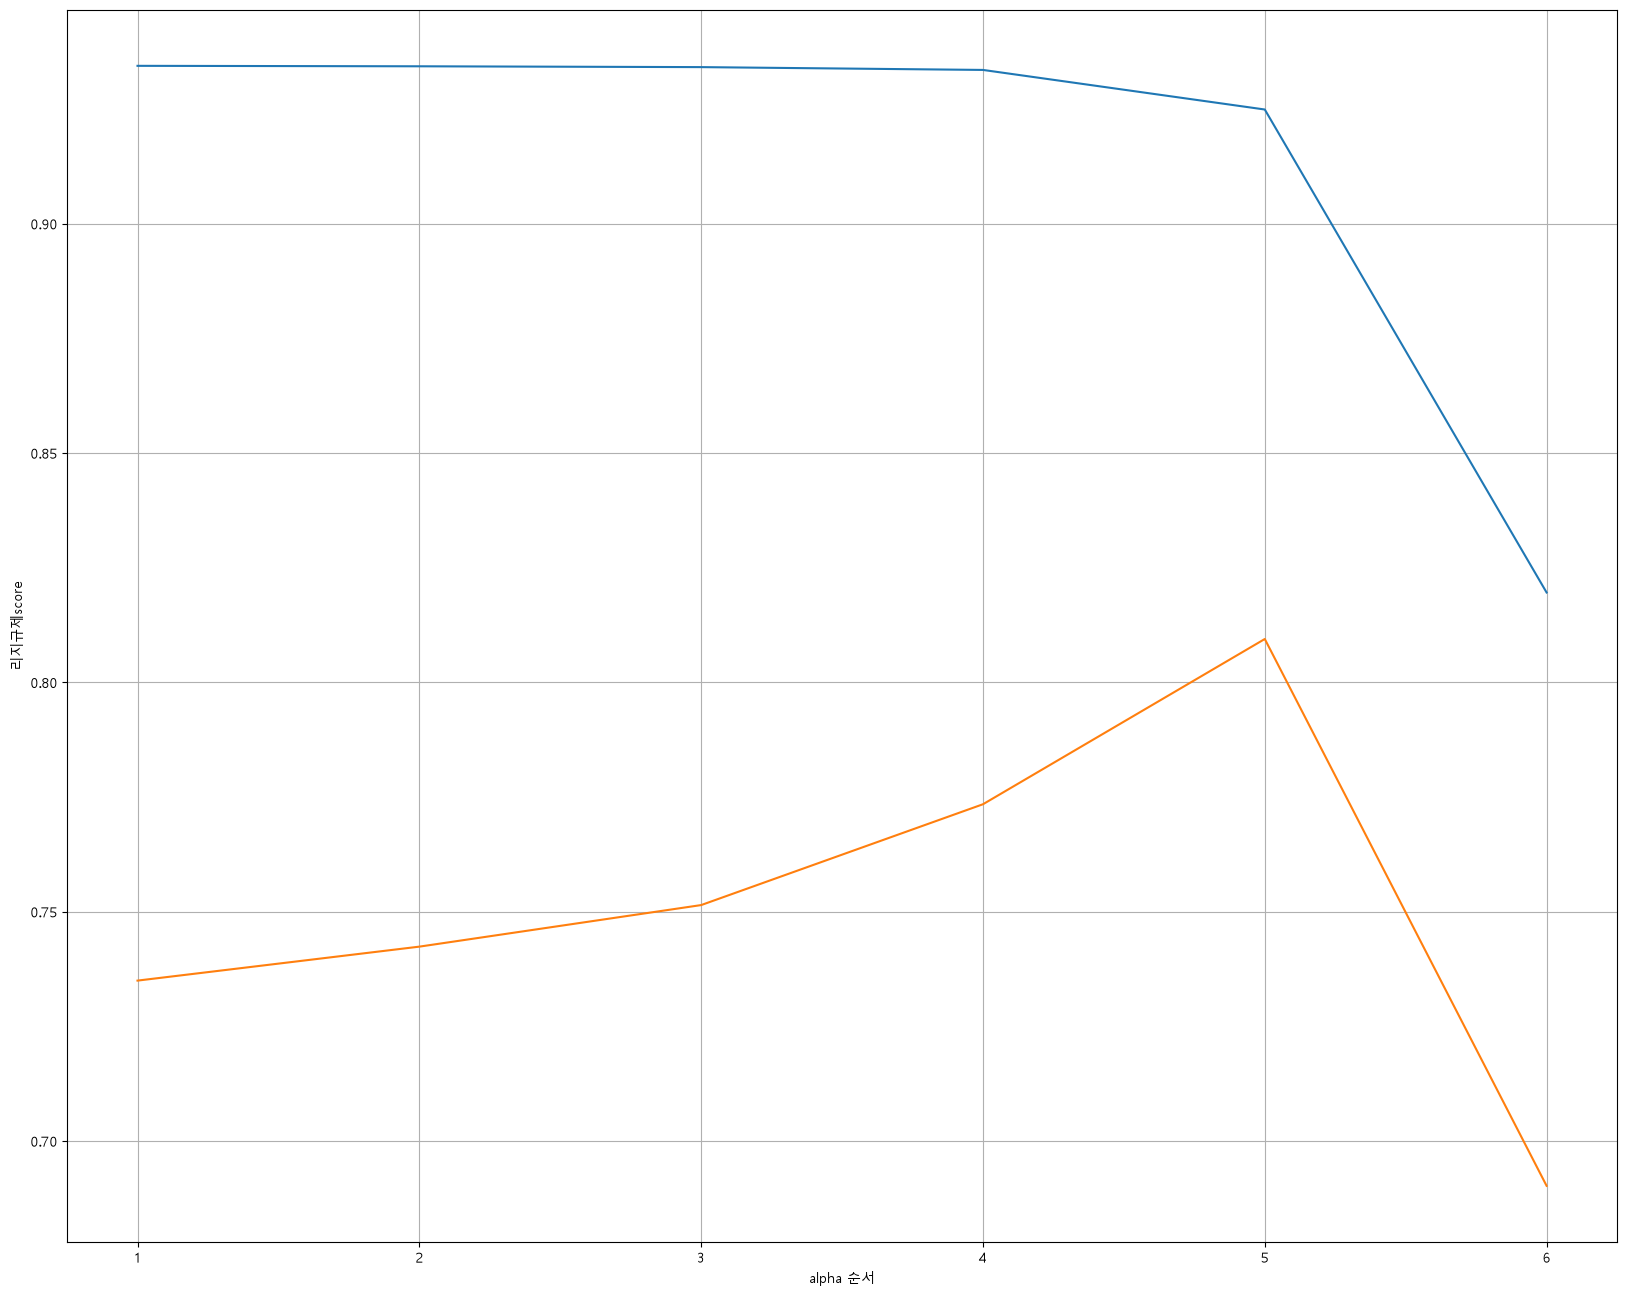

In [23]:
# 선그래프
no_list = [1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.xlabel('alpha 순서')
plt.ylabel('리지규제score')
plt.grid()
plt.show()

In [24]:
ridge = Ridge(alpha=10)
model = ridge.fit(train_scaled,train_label)
# 정확도
score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)
print('train 정확도 : ',score)
print('test 정확도 : ',score2)

train 정확도 :  0.9249253914492839
test 정확도 :  0.8094794963343103


In [25]:
data.columns

Index(['BABIP', 'ERA', 'FIP', 'LOB%', 'RA9-WAR', 'WAR', 'kFIP', '경기', '볼넷/9',
       '블론', '삼진/9', '선발', '세', '승', '연봉(2017)', '이닝', '패', '홀드', '홈런/9'],
      dtype='str')

In [16]:
# pip install statsmodels
# 회귀분석 통계결과표 : P>|t| 통계량의 절대값보다 크거나 같은 값이 나올 확률
import statsmodels.api as sm

train_scaled = sm.add_constant(train_scaled)
model = sm.OLS(train_label,train_scaled).fit()
model.summary()

# P>|t| 가 0에 가까울수록 영향이 크다

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.924
Model:                            OLS   Adj. R-squared:                  0.910
Method:                 Least Squares   F-statistic:                     64.82
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           7.33e-48
Time:                        16:39:44   Log-Likelihood:                -1275.4
No. Observations:                 121   AIC:                             2591.
Df Residuals:                     101   BIC:                             2647.
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.994e+04    910.214     21.910      0.000    1.81e+04    2.17e+04
x1          4395.5745   2832.591      1.552      0.124   -1223.523       1e+04
x2          -181.0170   2115.039     -0.086      0.932   -4376.685    4014.651
x3          -234.6394   1433.605     -0.164      0.870   -3078.526    2609.247
x4          -795.8327   1600.092     -0.497      0.620   -3969.984    2378.319
x5          1065.2349   1426.553      0.747      0.457   -1764.663    3895.133
x6         -3422.0279   3647.550     -0.938      0.350   -1.07e+04    3813.730
x7         -8453.0994   6349.147     -1.331      0.186    -2.1e+04    4141.901
x8          4745.0565   7900.707      0.601      0.549   -1.09e+04    2.04e+04
x9          -418.3394   6628.438     -0.063      0.950   -1.36e+04    1.27e+04
x10         4632.3840   6396.429      0.724      0.471   -8056.411    1.73e+04
x11         9142.2129   1.68e+04      0.545      0.587   -2.42e+04    4.24e+04
x12        -1426.0658   1508.920     -0.945      0.347   -4419.358    1567.226
x13         -608.9750   1772.873     -0.343      0.732   -4125.877    2907.928
x14          306.5617   2782.269      0.110      0.912   -5212.711    5825.835
x15         -659.3270   3311.941     -0.199      0.843   -7229.328    5910.674
x16        -3.685e+04   9.94e+04     -0.371      0.711   -2.34e+05     1.6e+05
x17         2.787e+04   8.29e+04      0.336      0.737   -1.37e+05    1.92e+05
x18         1.253e+04   2977.444      4.207      0.000    6618.758    1.84e+04
x19         2.285e+04   1347.093     16.960      0.000    2.02e+04    2.55e+04
==============================================================================
Omnibus:                       32.192   Durbin-Watson:                   1.801
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              432.406
Skew:                           0.029   Prob(JB):                     1.27e-94
Kurtosis:                      12.261   Cond. No.                         377.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [17]:
# 결정하는 결과에 영향을 미치는 것을 파악

plt.rcParams['figure.figsize'] = [20, 16]

# 회귀 계수를 리스트로 반환합니다.
coefs = model.params.tolist()
coefs_series = pd.Series(coefs)

# 변수명을 리스트로 반환합니다.
x_labels = model.params.index.tolist()

# 회귀 계수를 출력합니다.
ax = coefs_series.plot(kind='bar')
ax.set_title('feature_coef_graph')
ax.set_xlabel('x_features')
ax.set_ylabel('coef')
ax.set_xticklabels(x_labels)

AttributeError: 'numpy.ndarray' object has no attribute 'index'

In [ ]:
# pip install seaborn
import seaborn as sns

# 피처간의 상관계수 행렬을 계산
corr = picher[data.columns].corr(method='pearson')
show_cols = ['win', 'lose', 'save', 'hold', 'blon', 'match', 'start',
             'inning', 'strike3', 'ball4', 'homerun', 'BABIP', 'LOB',
             'ERA', 'RA9-WAR', 'FIP', 'kFIP', 'WAR', '2017']

# corr 행렬 히트맵을 시각화합니다.
# plt.rc('font', family='NanumGothicOTF')

hm = sns.heatmap(corr.values,
            cbar=True,
            annot=True,
            square=True,
            fmt='.2f',
            annot_kws={'size': 15},
            yticklabels=show_cols,
            xticklabels=show_cols)

plt.tight_layout()
plt.show()